# Project 2: Numerical Integration For Charged Particles

### Classical Runge-Kutta 4 on the extended system

In [132]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import scipy 

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
from functools import partial
import time as pytime
import time


#### Model problems 

In [133]:
# 2D charged particle

# The static magnetic field
def B_2D(x):
    return np.array([0, 0, np.sqrt(x[0]**2 + x[1]**2)])

def B_2D_np(x):
    return np.array([0, 0, np.sqrt(x[0]**2 + x[1]**2)])


# The vector potential
def A_2D(x):
    Ax = -x[1] * np.sqrt(x[0]**2 + x[1]**2)
    Ay = x[0] * np.sqrt(x[0]**2 + x[1]**2)
    Az = 0
    return 1/3 * np.array([Ax, Ay, Az])


# The electrostatic potential
def U_2D(x):
    return 1 / (100 * np.sqrt(x[0]**2 + x[1]**2))


# The gradient of the electrostatic potential
def grad_U_2D(x):
    Ux = x[0] / ((x[0]**2 + x[1]**2)**(3/2))
    Uy = x[1] / ((x[0]**2 + x[1]**2)**(3/2))
    Uz = 0
    return -1/100 * np.array([Ux, Uy, Uz])


def grad_U_2D_np(x):
    Ux = x[0] / ((x[0]**2 + x[1]**2)**(3/2))
    Uy = x[1] / ((x[0]**2 + x[1]**2)**(3/2))
    Uz = 0
    return -1/100 * np.array([Ux, Uy, Uz])


# Initial values
x0_2D = np.array([0.0, 1.0, 0.1], dtype=np.float64)
v0_2D = np.array([0.09, 0.05, 0.20], dtype=np.float64)

In [134]:
# Tokamak magnetic field

# The static magnetic field
def B_tokamak(x):
    Bx = -(2*x[1] + x[0]*x[2]) / (2*(x[0]**2 + x[1]**2))
    By = (2*x[0] - x[1]*x[2]) / (2*(x[0]**2 + x[1]**2))
    Bz = (np.sqrt(x[0]**2 + x[1]**2) - 1) / (2*np.sqrt(x[0]**2 + x[1]**2))
    return np.array([Bx, By, Bz])


def B_tokamak_np(x):
    Bx = -(2*x[1] + x[0]*x[2]) / (2*(x[0]**2 + x[1]**2))
    By = (2*x[0] - x[1]*x[2]) / (2*(x[0]**2 + x[1]**2))
    Bz = (np.sqrt(x[0]**2 + x[1]**2) - 1) / (2*np.sqrt(x[0]**2 + x[1]**2))
    return np.array([Bx, By, Bz])


# The vector potential
def A_tokamak(x):
    Ax = 0
    Ay = 1/2 * (x[0] - np.log(np.sqrt(x[0]**2 + x[1]**2) + x[0]))
    Az = -1/2 * (x[2]*np.arctan(x[1]/x[0]) + np.log(x[0]**2 + x[1]**2))
    return np.array([Ax, Ay, Az])


# The electrostatic potential
def U_tokamak(x):
    return 0


# The gradient of the electrostatic potential
def grad_U_tokamak(x):
    return 0


# Initial values
x0_tokamak = np.array([1.2, 0.0, 0.0], dtype=np.float64)
v0_tokamak = np.array([0, 4.816*1e-4, -2.059*1e-3], dtype=np.float64)

In [136]:
#defining the numerical approximation of the derivative
#adding B and grad U as parameters so that I can reuse the functions for both models

def ODEs(t, y, B, grad_U):
    x = y[:3]
    v = y[3:]

    dxdt = v
    dvdt = np.cross(v, B(x)) - grad_U(x)
    return np.concatenate((dxdt, dvdt))


#Defining the Runge Kutta 4 method

def RK4(y_n, h, B, grad_U):
    k_1 = h * ODEs(0, y_n, B, grad_U)
    k_2 = h * ODEs(0, y_n + 0.5*k_1, B, grad_U)
    k_3 = h * ODEs(0, y_n + 0.5*k_2, B, grad_U)
    k_4 = h * ODEs(0, y_n + k_3, B, grad_U)

    return y_n + (k_1 + 2*k_2 + 2*k_3 + k_4)/6




## A - Plotting trajectories and error over long time

In [138]:
# Parameters
T = 1e5
h = 0.1
n_steps = int(T/h)
time = np.linspace(0, T, n_steps + 1)

# Preallocating arrays
y_arr_2D = np.zeros((n_steps + 1, 6))

# Initial condition: position + velocity
y_arr_2D[0] = np.concatenate((np.asarray(x0_2D), np.asarray(v0_2D)))

y_n = np.concatenate((x0_2D, v0_2D))

for i in tqdm(range(n_steps)):
    y_n = RK4(y_n, h, B_2D, grad_U_2D)
    y_arr_2D[i+1] = np.asarray(y_n)

# Extracting position and velocity
x_arr_2D = y_arr_2D[:, :3]
v_arr_2D = y_arr_2D[:, 3:]
    
       

100%|██████████| 1000000/1000000 [01:06<00:00, 15051.86it/s]


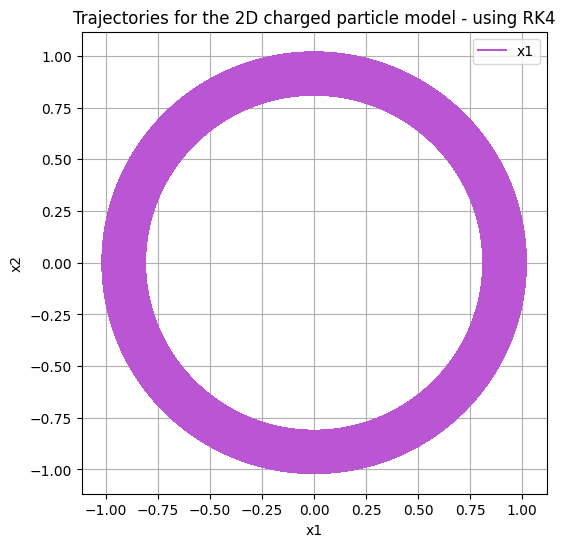

In [139]:
#Plotting the trajectories of the two first coordinates of the solutions
plt.figure(figsize=(6,6))
plt.plot(x_arr_2D[:, 0],x_arr_2D[:, 1], color = 'mediumorchid', label = 'x1')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Trajectories for the 2D charged particle model - using RK4')
plt.legend()
plt.grid(True)
plt.show()


In [140]:
# Parameters
T = 1e5
h = 0.1
n_steps = int(T/h)
time = np.linspace(0, T, n_steps + 1)

# Preallocating array
y_arr_tokamak = np.zeros((n_steps + 1, 6))

# Initial condition: position + velocity
y_arr_tokamak[0] = np.concatenate((
    np.asarray(x0_tokamak), np.asarray(v0_tokamak)))

y_n = np.concatenate((x0_tokamak, v0_tokamak))

for i in tqdm(range(n_steps)):
    y_n = RK4(y_n, h, B_tokamak, grad_U_tokamak)
    y_arr_tokamak[i+1] = np.asarray(y_n)

# Extracting position and velocity
x_arr_tokamak = y_arr_tokamak[:, :3]
v_arr_tokamak = y_arr_tokamak[:, 3:]

100%|██████████| 1000000/1000000 [01:11<00:00, 13933.26it/s]


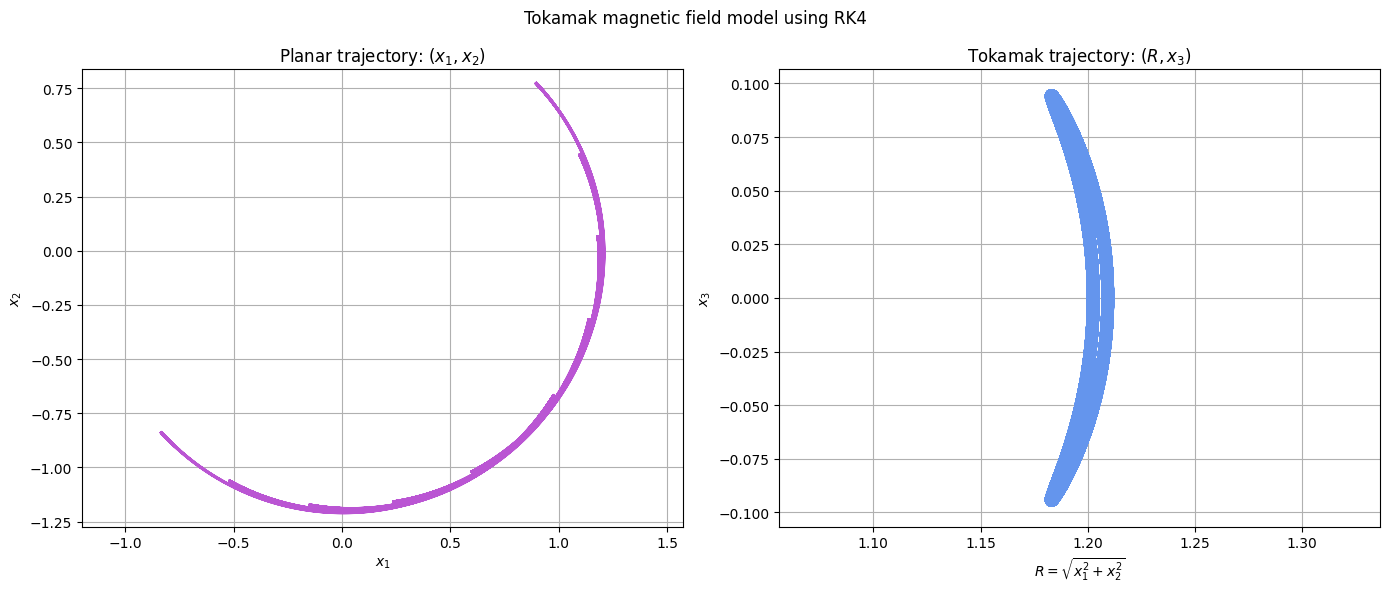

In [141]:
#Plotting the trajectories of the two first coordinates of the solutions
# Cylindrical radial coordinate
R = np.sqrt(x_arr_tokamak[:, 0]**2 + x_arr_tokamak[:, 1]**2)
x3 = x_arr_tokamak[:, 2]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Trajectory in the x1-x2 plane
axes[0].plot(x_arr_tokamak[:, 0],x_arr_tokamak[:, 1],color="mediumorchid")
axes[0].set_xlabel(r"$x_1$")
axes[0].set_ylabel(r"$x_2$")
axes[0].set_title(r"Planar trajectory: $(x_1,x_2)$")
axes[0].axis("equal")
axes[0].grid(True)

# Trajectory in the R-x3 plane
axes[1].plot(R,x3, color="cornflowerblue")
axes[1].set_xlabel(r"$R=\sqrt{x_1^2+x_2^2}$")
axes[1].set_ylabel(r"$x_3$")
axes[1].set_title(r"Tokamak trajectory: $(R,x_3)$")
axes[1].axis("equal")
axes[1].grid(True)

fig.suptitle("Tokamak magnetic field model using RK4")
plt.tight_layout()
plt.show()


---------------------------------------------------------------------------

In [142]:
#Testing for a shorter time interval because 
t_span_test = (0, 100)
t_eval_test = np.linspace(0, 100, 1001)

initial_condition_2D = np.concatenate((x0_2D,v0_2D))
initial_condition_tokamak = np.concatenate((x0_tokamak,v0_tokamak))


sol_test = scipy.integrate.solve_ivp(
    ODEs,
    t_span_test,
    initial_condition_2D,
    args=(B_2D, grad_U_2D),
    method='DOP853',
    rtol=1e-10,
    atol=1e-12,
    t_eval=t_eval_test
)

print("Success:", sol_test.success)
print("Function evaluations:", sol_test.nfev)
print("Message:", sol_test.message)

Success: True
Function evaluations: 5159
Message: The solver successfully reached the end of the integration interval.


In [143]:
#Plotting the error over time for the RK4 method
t_span = (0, T)
t_eval = np.arange(0, T+h, h)

initial_condition_2D = np.concatenate((x0_2D,v0_2D))
initial_condition_tokamak = np.concatenate((x0_tokamak,v0_tokamak))

sol_2D = scipy.integrate.solve_ivp(ODEs, t_span, initial_condition_2D, 
                                   args=(B_2D, grad_U_2D),
                                   method = 'DOP853',
                                   rtol = 1e-10,
                                   atol=1e-12,
                                   t_eval = t_eval)

sol_tokamak= scipy.integrate.solve_ivp(ODEs, t_span, initial_condition_tokamak, 
                                   args=(B_tokamak, grad_U_tokamak),
                                   method = 'DOP853',
                                   rtol = 1e-10,
                                   atol=1e-12,
                                   t_eval = t_eval)


print(sol_2D.success, sol_2D.message)
print(sol_tokamak.success, sol_tokamak.message)




True The solver successfully reached the end of the integration interval.
True The solver successfully reached the end of the integration interval.


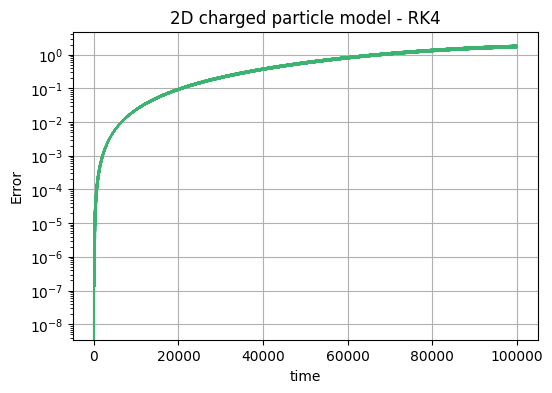

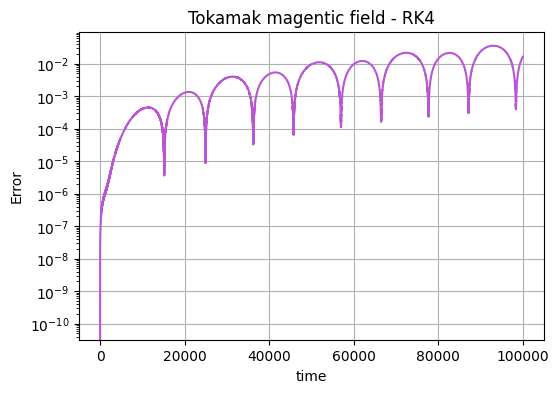

In [144]:
#Plotting the error over time for both 2D paticle model
#Transposing to switch the rows and columns to make the shapes match


error_2D = np.linalg.norm(x_arr_2D - sol_2D.y[:3, :].T, axis = 1)


plt.figure(figsize=(6,4))
plt.semilogy(t_eval, error_2D, color= 'mediumseagreen')
plt.xlabel('time')
plt.ylabel('Error')
plt.title('2D charged particle model - RK4')
plt.grid(True)
plt.show()

#Plotting the error over time for both Tokamak magnetic field
#Transposing to switch the rows and columns to make the shapes match
error_tokamak = np.linalg.norm(x_arr_tokamak - sol_tokamak.y[:3, :].T, axis = 1)


plt.figure(figsize=(6,4))
plt.semilogy(t_eval, error_tokamak, color= 'mediumorchid')
plt.xlabel('time')
plt.ylabel('Error')
plt.title('Tokamak magentic field - RK4')
plt.grid(True)
plt.show()


---------------------------------------------------------------

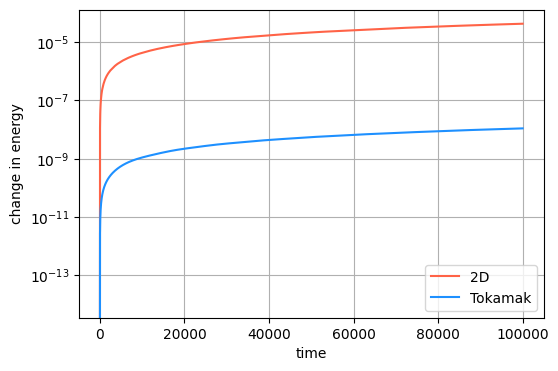

In [145]:
#Plotting the change in energy againt time 
#Defining the energyfunction
def energy(y, U):
    x = y[:, :3]
    v = y[:, 3:]

    return 0.5*np.linalg.norm(v, axis=1)**2 +np.array([float(U(x_i)) for x_i in x]) 

initial_condition_2D = np.concatenate((x0_2D,v0_2D))
initial_condition_tokamak = np.concatenate((x0_tokamak,v0_tokamak))

E0_2D = energy(initial_condition_2D.reshape(1, 6), U_2D)[0]
E0_tokamak = energy(initial_condition_tokamak.reshape(1, 6), U_tokamak)[0]

#Calculating the change in energy
e_n_2D = np.abs(energy(y_arr_2D, U_2D) - E0_2D)
e_n_tokamak = np.abs(energy(y_arr_tokamak, U_tokamak) - E0_tokamak)

#Plot
plt.figure(figsize=(6,4))
plt.semilogy(t_eval, e_n_2D, color= 'tomato', label = '2D')
plt.semilogy(t_eval, e_n_tokamak, color = 'dodgerblue', label = 'Tokamak')
plt.xlabel('time')
plt.ylabel('change in energy')
plt.legend()
plt.grid(True)
plt.show()

## Task B) Order verification and work precision diagrams

In [146]:

#Paramaters
h = 0.1
h_i = np.array([h, h/2 , h/4])


T = 1e4
N_i = (T/h_i).astype(int)

for i in range(3):
    print(h_i[i], N_i[i]*h_i[i])

#2D
# Preallocating arrays
y_arr_2D_i = [
    np.zeros((N_i[0] + 1, 6)),
    np.zeros((N_i[1] + 1, 6)), 
    np.zeros((N_i[2] + 1, 6))
    ]

# Initial condition: position + velocity
y0 = np.concatenate((np.asarray(x0_2D), np.asarray(v0_2D)))
                          
for i in range(3):
    y_arr_2D_i[i][0] = y0


tau_2D_i = []

for i in range(3):
    #Resetting y_n before each simulation
    y_n = np.concatenate((x0_2D, v0_2D))

    start = pytime.perf_counter()
    for j in tqdm(range(N_i[i])):
        y_n = RK4(y_n, h_i[i], B_2D, grad_U_2D)
        y_arr_2D_i[i][j+1] = np.asarray(y_n)

    end = pytime.perf_counter()
    tau_2D_i.append(end-start)
    

# Extracting position and velocity
x_arr_2D_i = [y[:, :3] for y in y_arr_2D_i]
v_arr_2D_i =[y[:, 3:] for y in y_arr_2D_i]



0.1 10000.0
0.05 10000.0
0.025 10000.0


100%|██████████| 400000/400000 [00:26<00:00, 14919.13it/s]


In [147]:
#Tokamak
# Preallocating array
y_arr_tokamak_i = [
    np.zeros((N_i[0] + 1, 6)),
    np.zeros((N_i[1] + 1, 6)), 
    np.zeros((N_i[2] + 1, 6))
    ]


# Initial condition: position + velocity
y0 = np.concatenate((np.asarray(x0_tokamak), np.asarray(v0_tokamak)))

for i in range(3):
    y_arr_tokamak_i[i][0] = y0

tau_tokamak_i = []

for i in range(3):
    #Resetting y_n before each simulation
    y_n = np.concatenate((x0_tokamak, v0_tokamak))

    start = pytime.perf_counter()

    for j in tqdm(range(N_i[i])):
        y_n = RK4(y_n, h_i[i], B_tokamak, grad_U_tokamak)
        y_arr_tokamak_i[i][j+1] = np.asarray(y_n)
    end = pytime.perf_counter()
    tau_tokamak_i.append(end-start)


# Extracting position and velocity
x_arr_tokamak_i = [y[:, :3] for y in y_arr_tokamak_i]
v_arr_tokamak_i =[y[:, 3:] for y in y_arr_tokamak_i]

print(tau_tokamak_i)

100%|██████████| 400000/400000 [00:28<00:00, 13830.07it/s]

[7.070081084006233, 14.278191249992233, 28.924469916004455]


In [148]:
#Solve_ivp for all three step sizes
sol_2D_i = []
sol_tokamak_i = []

for i in range(3):
    t_eval_i = np.arange(0, T + h_i[i]/2, h_i[i])
    sol_2D_i.append(
        scipy.integrate.solve_ivp(ODEs, (0, T), initial_condition_2D, 
                args=(B_2D, grad_U_2D),
                method = 'DOP853',
                rtol = 1e-10,
                atol=1e-12,
                t_eval = t_eval_i)

    )
    
    sol_tokamak_i.append(
        scipy.integrate.solve_ivp(ODEs, (0, T), initial_condition_tokamak, 
                args=(B_tokamak, grad_U_tokamak),
                method = 'DOP853',
                rtol = 1e-10,
                atol=1e-12,
                t_eval = t_eval_i)

    )
    

for i in range(3):
    print(f"h = {h_i[i]}:")
    print(sol_2D_i[i].success, sol_2D_i[i].message)
    print(sol_tokamak_i[i].success, sol_tokamak_i[i].message)

h = 0.1:
True The solver successfully reached the end of the integration interval.
True The solver successfully reached the end of the integration interval.
h = 0.05:
True The solver successfully reached the end of the integration interval.
True The solver successfully reached the end of the integration interval.
h = 0.025:
True The solver successfully reached the end of the integration interval.
True The solver successfully reached the end of the integration interval.


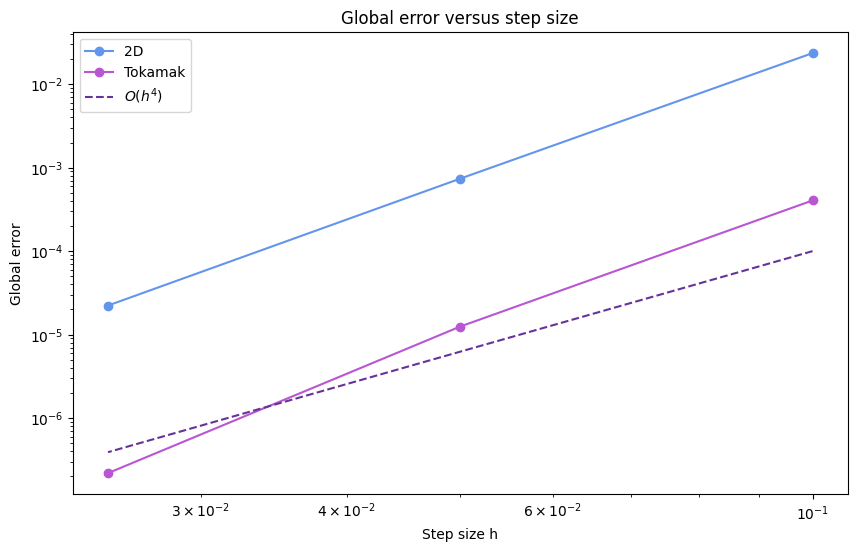

In [149]:
#Comuting the error in the last step
error_2D_i = []

for i in range(3):
    error_2D_i.append(np.linalg.norm(x_arr_2D_i[i][-1, :] - sol_2D_i[i].y[:3, -1]))


error_tokamak_i = []

for i in range(3):
    error_tokamak_i.append(np.linalg.norm(x_arr_tokamak_i[i][-1, :] - sol_tokamak_i[i].y[:3, -1]))


#Plotting
plt.figure(figsize=(10,6))

plt.loglog(h_i, error_2D_i, 'o-', label='2D', color= 'cornflowerblue')
plt.loglog(h_i, error_tokamak_i, 'o-', label='Tokamak', color= 'mediumorchid')

plt.loglog(h_i, h_i**4, '--', label=r'$O(h^4)$', color= 'rebeccapurple')

plt.xlabel('Step size h')
plt.ylabel('Global error')
plt.title('Global error versus step size')
plt.legend()

plt.show()


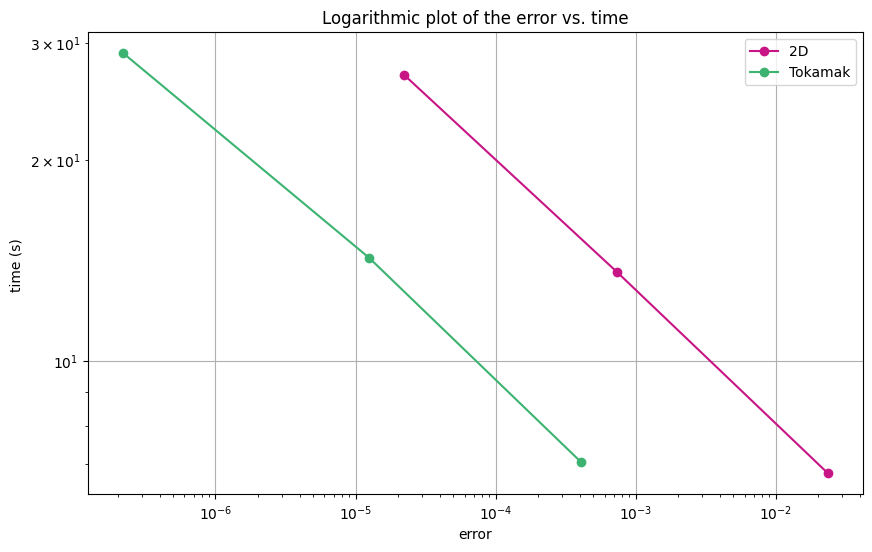

In [150]:
#plotting the error vs. time with the RK4 method

plt.figure(figsize=(10, 6))
plt.loglog(error_2D_i, tau_2D_i, 'o-' , color = 'mediumvioletred', label = '2D')
plt.loglog(error_tokamak_i, tau_tokamak_i, 'o-', color = 'mediumseagreen', label = 'Tokamak')
plt.xlabel('error')
plt.ylabel('time (s) ')
plt.title('Logarithmic plot of the error vs. time')
plt.legend()
plt.grid(True)
plt.show()

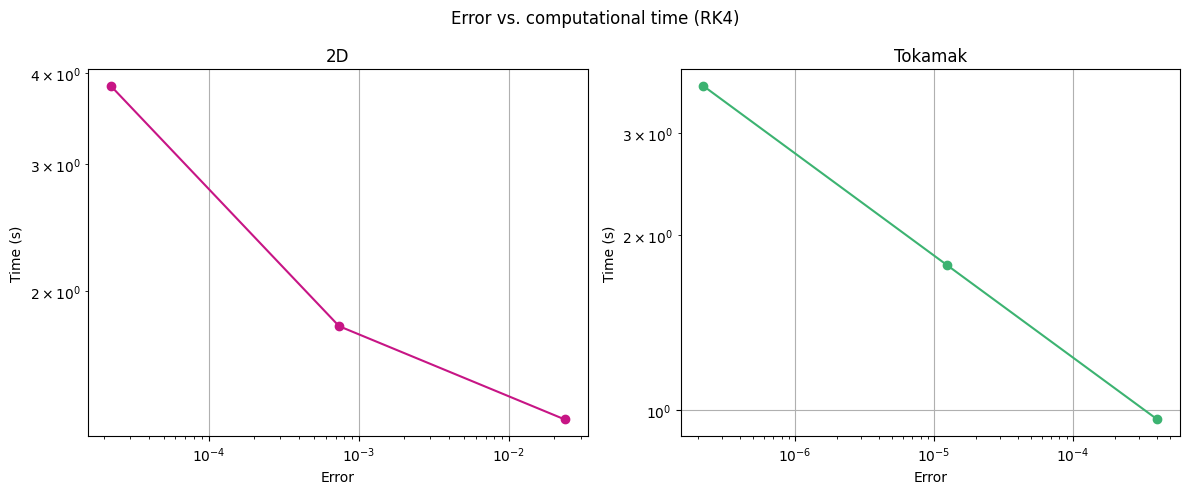

In [131]:
#The same only this time in two subplots

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# 2D
ax[0].loglog(error_2D_i, tau_2D_i, 'o-', color='mediumvioletred')
ax[0].set_xlabel('Error')
ax[0].set_ylabel('Time (s)')
ax[0].set_title('2D')
ax[0].grid(True)

# Tokamak
ax[1].loglog(error_tokamak_i, tau_tokamak_i, 'o-', color='mediumseagreen')
ax[1].set_xlabel('Error')
ax[1].set_ylabel('Time (s)')
ax[1].set_title('Tokamak')
ax[1].grid(True)

fig.suptitle('Error vs. computational time (RK4)')
plt.tight_layout()
plt.show()